# FD001 data loading and exploratory analysis

This notebook loads the NASA C-MAPSS FD001 files, creates the training RUL label, and identifies flat columns that can be removed before modeling.

In [1]:
import sys
sys.path.append("../src")
from load_data import ALL_SENSORS, FLAT_COLUMNS, SENSORS, SETTINGS, load_test, load_test_rul, load_train

## Shapes

The training and test files contain one row per engine cycle. This section checks their dimensions, engine counts, and missing values.

In [2]:
import pandas as pd

train = load_train()
test = load_test()

print(f"Train shape: {train.shape}")
print(f"Test shape: {test.shape}")
print(f"Train engines: {train['engine_id'].nunique()}")
print(f"Test engines: {test['engine_id'].nunique()}")
print(f"Train missing values: {train.isna().sum().sum()}")
print(f"Test missing values: {test.isna().sum().sum()}")

Train shape: (20631, 27)
Test shape: (13096, 26)
Train engines: 100
Test engines: 100
Train missing values: 0
Test missing values: 0


## Engine lifetimes

Because every training engine runs through failure, its final observed cycle is its lifetime in cycles. The histogram shows the range of lifetimes across the 100 engines.

Lifetime min: 128
Lifetime mean: 206.31
Lifetime max: 362


Text(0.5, 1.0, 'Training engine lifetimes')

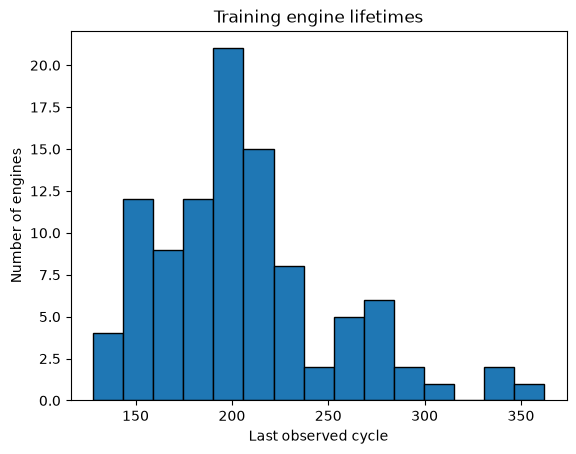

In [3]:
lifetimes = train.groupby("engine_id")["cycle"].max()
print(f"Lifetime min: {lifetimes.min()}")
print(f"Lifetime mean: {lifetimes.mean():.2f}")
print(f"Lifetime max: {lifetimes.max()}")

ax = lifetimes.plot.hist(bins=15, edgecolor="black")
ax.set_xlabel("Last observed cycle")
ax.set_ylabel("Number of engines")
ax.set_title("Training engine lifetimes")

## RUL label

For training engines, RUL is the engine's final cycle minus the current cycle. The first row of engine 1 therefore has RUL 191, and its final row has RUL 0.

In [4]:
engine_1 = train.loc[train["engine_id"] == 1, ["engine_id", "cycle", "rul"]]
display(engine_1.head(3))
display(engine_1.tail(3))

,engine_id,cycle,rul
0,1,1,191
1,1,2,190
2,1,3,189


,engine_id,cycle,rul
189,1,190,2
190,1,191,1
191,1,192,0


## Sensor trends

These four sensors are plotted against RUL for engines 1–5. The x-axis is inverted so failure (RUL 0) is on the right; most sensors remain fairly flat for much of the life and change more clearly near failure.

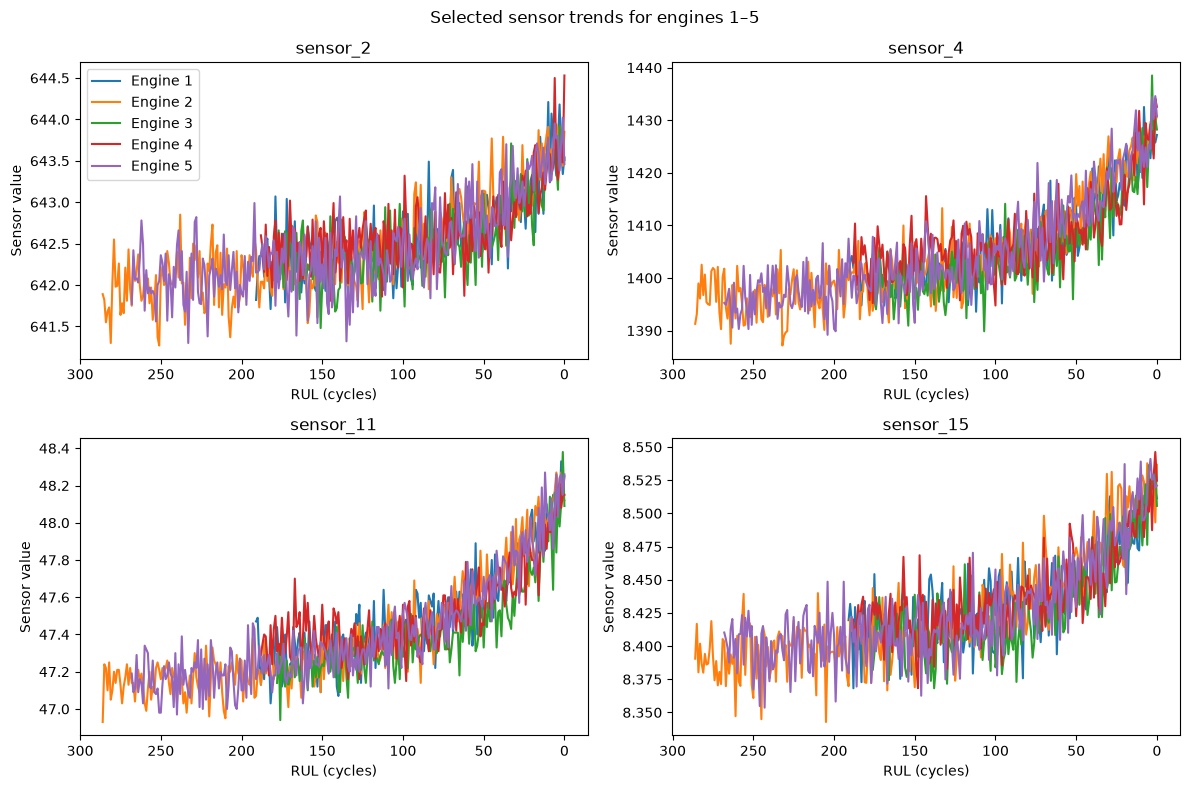

In [5]:
import matplotlib.pyplot as plt

trend_sensors = ["sensor_2", "sensor_4", "sensor_11", "sensor_15"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=False)
for ax, sensor in zip(axes.flat, trend_sensors):
    for engine_id in range(1, 6):
        engine = train.loc[train["engine_id"] == engine_id]
        ax.plot(engine["rul"], engine[sensor], label=f"Engine {engine_id}")
    ax.invert_xaxis()
    ax.set_title(sensor)
    ax.set_xlabel("RUL (cycles)")
    ax.set_ylabel("Sensor value")
axes[0, 0].legend()
fig.suptitle("Selected sensor trends for engines 1–5")
fig.tight_layout()

## Flat columns

For every setting and sensor, the table reports the share of rows containing its most common value. Columns with a share of at least 0.95 are treated as flat because they carry little wear information.

In [6]:
measurement_columns = SETTINGS + ALL_SENSORS
common_value_share = pd.Series(
    {
        col: train[col].value_counts(normalize=True).iloc[0]
        for col in measurement_columns
    },
    name="most_common_value_share",
).sort_values(ascending=False)
display(common_value_share.to_frame())
print("Flat columns (share >= 0.95):")
print(common_value_share[common_value_share >= 0.95].index.tolist())

,most_common_value_share
sensor_10,1.000000
setting_3,1.000000
sensor_1,1.000000
sensor_19,1.000000
sensor_18,1.000000
sensor_5,1.000000
sensor_16,1.000000
sensor_6,0.980321
sensor_17,0.263923
setting_2,0.101982


Flat columns (share >= 0.95):
['sensor_10', 'setting_3', 'sensor_1', 'sensor_19', 'sensor_18', 'sensor_5', 'sensor_16', 'sensor_6']


## Correlation

The heatmap shows pairwise Pearson correlations among the 14 non-flat sensors. Highly correlated pairs (absolute correlation at least 0.8) are listed below.

,sensor_a,sensor_b,correlation
0,sensor_9,sensor_14,0.963157
1,sensor_11,sensor_12,-0.846884
2,sensor_4,sensor_11,0.830136
3,sensor_8,sensor_13,0.826084
4,sensor_7,sensor_11,-0.822805
5,sensor_4,sensor_12,-0.815591
6,sensor_7,sensor_12,0.812713


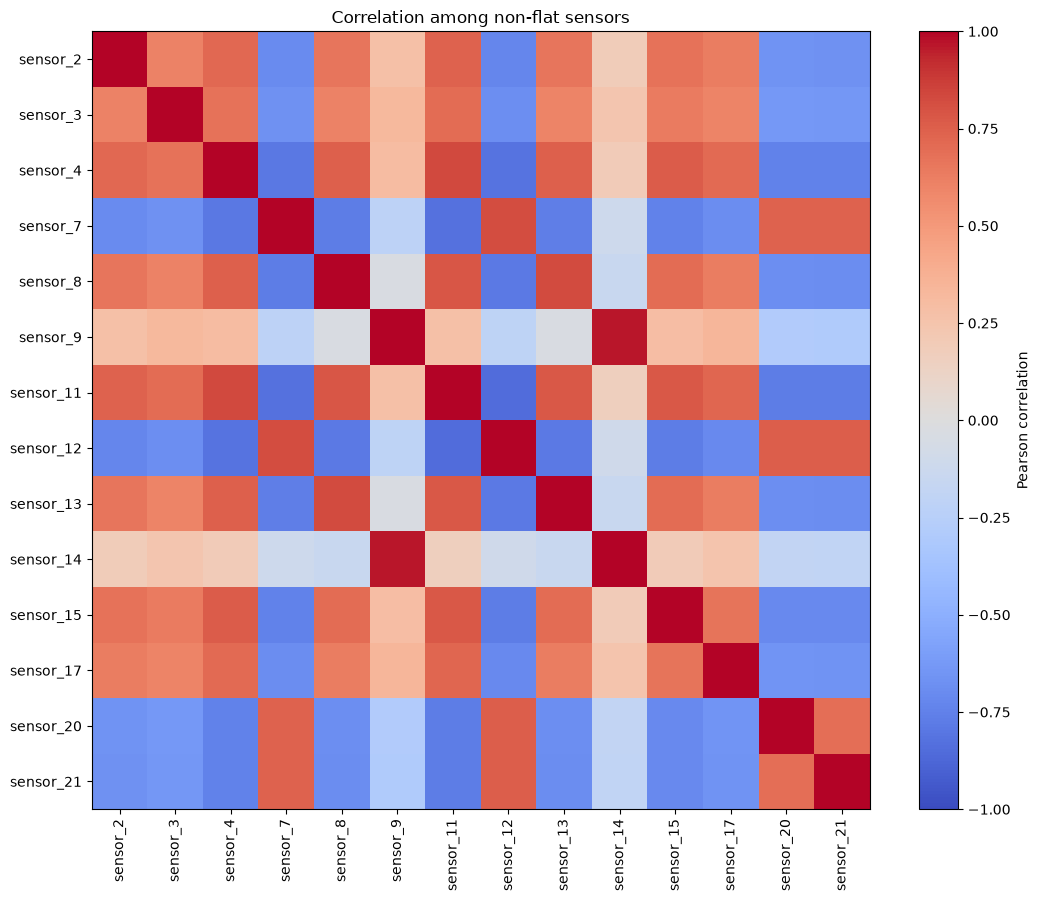

In [7]:
correlation = train[SENSORS].corr()
fig, ax = plt.subplots(figsize=(11, 9))
image = ax.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(SENSORS)), labels=SENSORS, rotation=90)
ax.set_yticks(range(len(SENSORS)), labels=SENSORS)
fig.colorbar(image, ax=ax, label="Pearson correlation")
plt.title("Correlation among non-flat sensors")
plt.tight_layout()

high_correlations = []
for i, sensor_a in enumerate(SENSORS):
    for sensor_b in SENSORS[i + 1:]:
        value = correlation.loc[sensor_a, sensor_b]
        if abs(value) >= 0.8:
            high_correlations.append((sensor_a, sensor_b, value))
high_correlations.sort(key=lambda pair: abs(pair[2]), reverse=True)
display(pd.DataFrame(high_correlations, columns=["sensor_a", "sensor_b", "correlation"]))

## Operating condition

FD001 has one operating condition: `setting_1` and `setting_2` barely change and `setting_3` is constant, so no per-condition normalisation is needed.

In [8]:
display(train[SETTINGS].describe())

,setting_1,setting_2,setting_3
count,20631.000000,20631.000000,20631.0
mean,-0.000009,0.000002,100.0
std,0.002187,0.000293,0.0
min,-0.008700,-0.000600,100.0
25%,-0.001500,-0.000200,100.0
50%,0.000000,0.000000,100.0
75%,0.001500,0.000300,100.0
max,0.008700,0.000600,100.0


## Test file

Test engines stop before failure, so their observed cycle counts describe only the available history. The supplied RUL file is loaded and its shape is checked, but its values are not displayed because they are reserved for final evaluation.

In [9]:
test_cycles = test.groupby("engine_id")["cycle"].max()
print(f"Observed test cycles per engine: min={test_cycles.min()}, max={test_cycles.max()}")
print(f"Test RUL shape: {load_test_rul().shape}")

Observed test cycles per engine: min=31, max=303
Test RUL shape: (100, 2)
